# Andy Trader: Does Kronos Beat a Coin Flip on Our Candles?

## Name: Dawn Andrei Pamesa


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Loading the Replayed Forecasts

In [2]:
forecasts = pd.read_csv("../research_data/kronos_backtest.csv")
forecasts.head()

,instrument,reference_time,reference_price,share_up_4h,share_up_1d,actual_4h,actual_1d
0,BTC-USD,2026-10-16 02:00:00,82099.5,0.20,0.40,82080.2,81623.0
1,BTC-USD,2026-10-16 05:00:00,82351.9,0.00,0.45,82187.3,81578.0
2,BTC-USD,2026-10-16 08:00:00,82333.0,0.20,0.25,82506.2,81721.9
3,BTC-USD,2026-10-16 11:00:00,82266.2,0.05,0.20,81875.9,81617.7
4,BTC-USD,2026-10-16 14:00:00,82035.5,0.15,0.65,81295.0,81502.5


In [3]:
print("Shape:", forecasts.shape)

Shape: (488, 7)


In [4]:
forecasts["instrument"].value_counts()

instrument
BTC-USD     61
ETH-USD     61
SOL-USD     61
XRP-USD     61
DOGE-USD    61
ADA-USD     61
AVAX-USD    61
LINK-USD    61
Name: count, dtype: int64

In [5]:
forecasts.describe()

,reference_price,share_up_4h,share_up_1d,actual_4h,actual_1d
count,488.000000,488.000000,488.000000,488.000000,488.000000
mean,10588.028139,0.301742,0.518852,10587.839795,10571.054357
std,27089.850415,0.194804,0.270643,27089.093316,27048.344957
min,0.076650,0.000000,0.000000,0.077010,0.076650
25%,1.005325,0.150000,0.300000,1.009125,1.004600
50%,10.986000,0.300000,0.500000,10.970500,10.820500
75%,666.875000,0.450000,0.750000,670.745000,666.875000
max,84581.600000,0.900000,1.000000,84706.300000,84581.600000


What Really Happened

In [6]:
forecasts["up_4h"] = (forecasts["actual_4h"] > forecasts["reference_price"]).astype(int)
forecasts["up_1d"] = (forecasts["actual_1d"] > forecasts["reference_price"]).astype(int)

In [7]:
print("Share of 4h windows that went up :", forecasts["up_4h"].mean())
print("Share of 1d windows that went up :", forecasts["up_1d"].mean())

Share of 4h windows that went up : 0.45081967213114754
Share of 1d windows that went up : 0.39344262295081966


Clamping Like the Live Predictor

In [8]:
forecasts["p_4h"] = forecasts["share_up_4h"].clip(0.02, 0.98)
forecasts["p_1d"] = forecasts["share_up_1d"].clip(0.02, 0.98)

Direction Hit Rate

In [9]:
hit_4h = ((forecasts["p_4h"] > 0.5) == (forecasts["up_4h"] == 1))[forecasts["p_4h"] != 0.5]
hit_1d = ((forecasts["p_1d"] > 0.5) == (forecasts["up_1d"] == 1))[forecasts["p_1d"] != 0.5]
print("4h hit rate :", hit_4h.mean(), "on", len(hit_4h), "calls")
print("1d hit rate :", hit_1d.mean(), "on", len(hit_1d), "calls")

4h hit rate : 0.5121951219512195 on 451 calls
1d hit rate : 0.485838779956427 on 459 calls


Brier Score Against Two Simple Baselines

In [10]:
# Brier score: mean squared gap between the probability and the 0/1 outcome. Lower is better.
brier_4h = ((forecasts["p_4h"] - forecasts["up_4h"]) ** 2).mean()
brier_1d = ((forecasts["p_1d"] - forecasts["up_1d"]) ** 2).mean()
print("Kronos 4h Brier :", brier_4h)
print("Kronos 1d Brier :", brier_1d)

Kronos 4h Brier : 0.3092592213114754
Kronos 1d Brier : 0.31814303278688527


In [11]:
coin_flip = 0.25
base_4h = ((forecasts["up_4h"].mean() - forecasts["up_4h"]) ** 2).mean()
base_1d = ((forecasts["up_1d"].mean() - forecasts["up_1d"]) ** 2).mean()
print("Coin flip Brier :", coin_flip)
print("Base rate 4h Brier :", base_4h)
print("Base rate 1d Brier :", base_1d)

Coin flip Brier : 0.25
Base rate 4h Brier : 0.24758129535071224
Base rate 1d Brier : 0.23864552539639883


In [12]:
print("Skill vs base rate, 4h :", 1 - brier_4h / base_4h)
print("Skill vs base rate, 1d :", 1 - brier_1d / base_1d)

Skill vs base rate, 4h : -0.24912191316146481
Skill vs base rate, 1d : -0.33311962274774776


Per Coin

In [13]:
by_coin = forecasts.groupby("instrument").apply(lambda g: pd.Series({
    "windows": len(g),
    "up_rate_1d": g["up_1d"].mean(),
    "hit_1d": ((g["p_1d"] > 0.5) == (g["up_1d"] == 1)).mean(),
    "brier_1d": ((g["p_1d"] - g["up_1d"]) ** 2).mean(),
}), include_groups=False)
by_coin

,windows,up_rate_1d,hit_1d,brier_1d
instrument,,,,
ADA-USD,61.0,0.311475,0.590164,0.264467
AVAX-USD,61.0,0.278689,0.508197,0.363208
BTC-USD,61.0,0.459016,0.573770,0.281092
DOGE-USD,61.0,0.426230,0.590164,0.239672
ETH-USD,61.0,0.426230,0.409836,0.302548
LINK-USD,61.0,0.409836,0.393443,0.400408
SOL-USD,61.0,0.426230,0.360656,0.356769
XRP-USD,61.0,0.409836,0.459016,0.336980


Calibration of the 1 Day Forecast

In [14]:
forecasts["bucket_1d"] = pd.cut(forecasts["p_1d"], [0, 0.2, 0.4, 0.6, 0.8, 1.0])
calibration = forecasts.groupby("bucket_1d", observed=True).agg(calls=("up_1d", "size"), said=("p_1d", "mean"), happened=("up_1d", "mean"))
calibration

,calls,said,happened
bucket_1d,,,
"(0.0, 0.2]",82,0.120732,0.292683
"(0.2, 0.4]",105,0.324286,0.485714
"(0.4, 0.6]",118,0.522458,0.381356
"(0.6, 0.8]",103,0.724272,0.378641
"(0.8, 1.0]",80,0.912000,0.412500


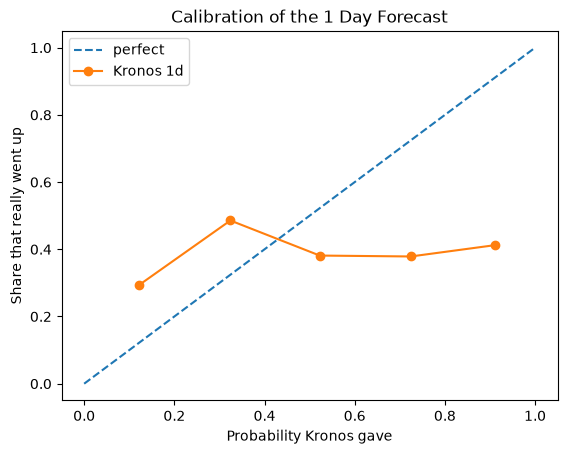

In [15]:
plt.plot([0, 1], [0, 1], "--", label="perfect")
plt.plot(calibration["said"], calibration["happened"], "o-", label="Kronos 1d")
plt.xlabel("Probability Kronos gave")
plt.ylabel("Share that really went up")
plt.title("Calibration of the 1 Day Forecast")
plt.legend()
plt.show()

How Much Independent Data Is This?

In [16]:
# Windows start every 3 hours but each looks 24 hours ahead, so neighbours overlap and move together.
print("Windows :", len(forecasts))
print("Roughly independent 1d calls per coin :", len(forecasts) / forecasts["instrument"].nunique() / 8)
print("Days of history covered :", forecasts["reference_time"].nunique() * 3 / 24)

Windows : 488
Roughly independent 1d calls per coin : 7.625
Days of history covered : 7.625


Summary

In [17]:
print("Kronos was replayed on", len(forecasts), "past windows over", forecasts["instrument"].nunique(), "coins.")
print("1 day direction hit rate was", round(hit_1d.mean(), 3), "and its Brier skill versus always saying the base rate was", round(1 - brier_1d / base_1d, 3), ".")
print("4 hour direction hit rate was", round(hit_4h.mean(), 3), "and its Brier skill was", round(1 - brier_4h / base_4h, 3), ".")
print("Neighbouring windows overlap and the period is about", round(forecasts["reference_time"].nunique() * 3 / 24), "days of one market mood, so this is a rough read, not proof.")

Kronos was replayed on 488 past windows over 8 coins.
1 day direction hit rate was 0.486 and its Brier skill versus always saying the base rate was -0.333 .
4 hour direction hit rate was 0.512 and its Brier skill was -0.249 .
Neighbouring windows overlap and the period is about 8 days of one market mood, so this is a rough read, not proof.
